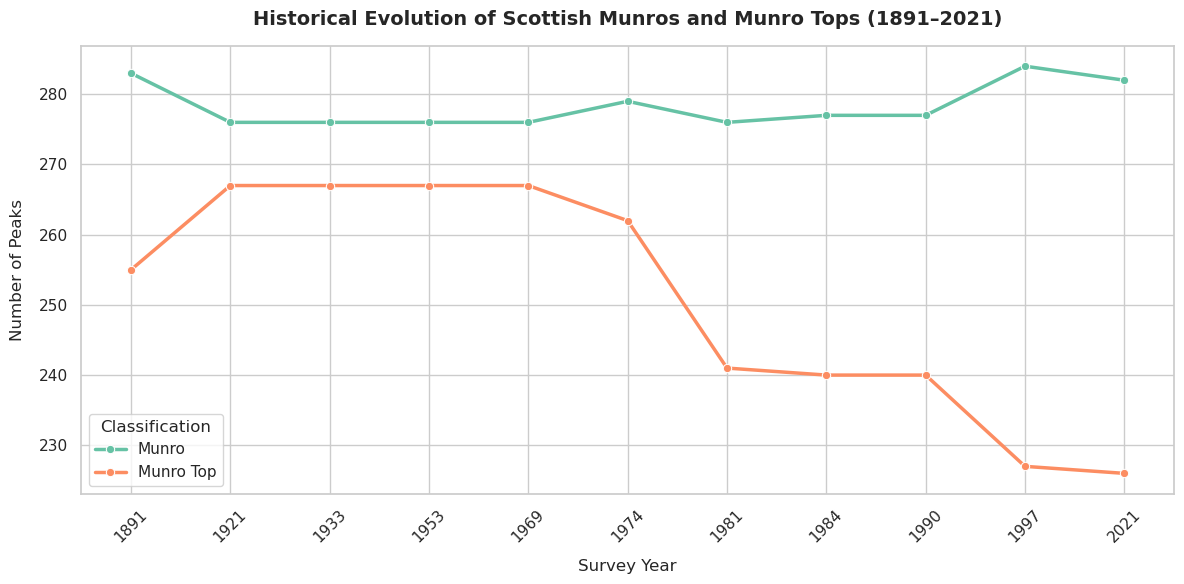

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Scottish Munros dataset with latin1 encoding to fix the Unicode error
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-08-19/scottish_munros.csv'
df = pd.read_csv(url, encoding='latin1')

# 2. Define the historical classification year columns
year_cols = ['1891', '1921', '1933', '1953', '1969', '1974', '1981', '1984', '1990', '1997', '2021']

# 3. Compute the counts for 'Munro' and 'Munro Top' for each survey year
trend_data = []
for year in year_cols:
    if year in df.columns:
        # Map raw file codes ('MUN' / 'TOP') to friendly labels
        mapped_series = df[year].replace({
            'MUN': 'Munro',
            'TOP': 'Munro Top'
        })
        counts = mapped_series.value_counts()
        trend_data.append({
            'Year': year,
            'Munro': counts.get('Munro', 0),
            'Munro Top': counts.get('Munro Top', 0)
        })

trend_df = pd.DataFrame(trend_data)

# 4. Reshape the dataframe for seaborn plotting
melted_df = trend_df.melt(id_vars='Year', value_vars=['Munro', 'Munro Top'], 
                          var_name='Classification', value_name='Count')

# 5. Set up the visualization style
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Create a line plot with distinct markers
sns.lineplot(
    data=melted_df, 
    x='Year', 
    y='Count', 
    hue='Classification', 
    marker='o', 
    linewidth=2.5, 
    palette='Set2'
)

# 6. Customize chart aesthetics
plt.title('Historical Evolution of Scottish Munros and Munro Tops (1891–2021)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Survey Year', fontsize=12, labelpad=10)
plt.ylabel('Number of Peaks', fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.legend(title='Classification', frameon=True)

# Adjust layout and display
plt.tight_layout()
plt.show()